✅ AI Grid Load-Balancer Accuracy: 99.00%
✅ Battery Degradation Model MAE: 0.0303


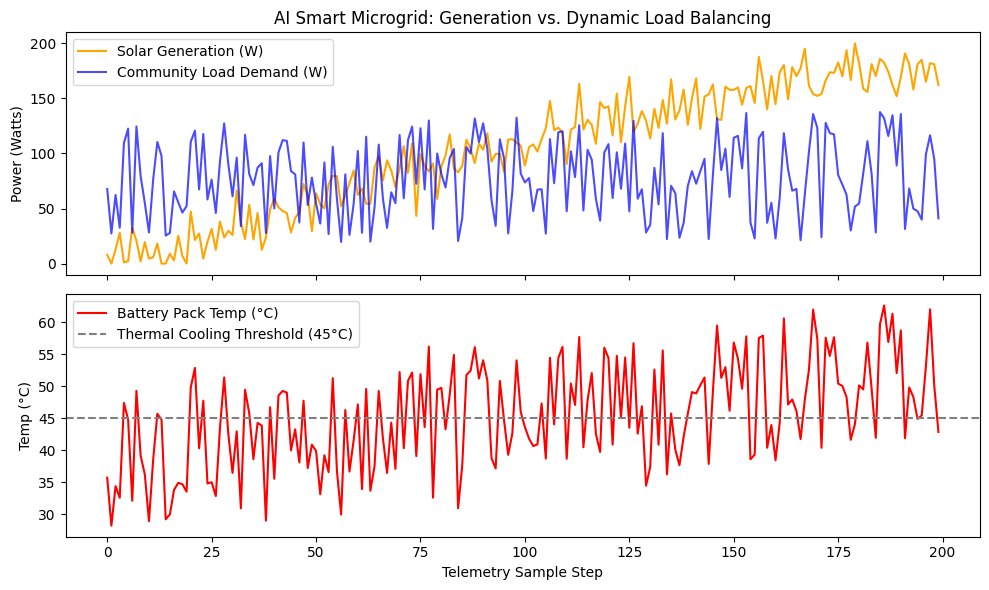

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error

# 1. Generate Physics-Based Microgrid Telemetry (2,000 samples)
np.random.seed(42)
n = 2000
time_ms = np.arange(0, n * 500, 500)
irradiance = np.clip(np.maximum(0, np.sin(np.linspace(0, 4*np.pi, n))) * 950 + np.random.normal(0, 80, n), 0, 1000)
demand_a = np.clip(np.random.uniform(1.5, 11.5, n), 0.5, 12.0)
batt_v = np.clip(12.8 + (irradiance - 500)*0.0015 - (demand_a - 5)*0.18 + np.random.normal(0, 0.15, n), 10.5, 14.4)
temp_c = np.clip(24.0 + (demand_a * 2.2) + (irradiance * 0.015) + np.random.normal(0, 2.0, n), 18.0, 72.0)

solar_w = irradiance * 0.20
demand_w = batt_v * demand_a
net_w = solar_w - demand_w

grid_state = [
    3 if (temp_c[i] >= 60.0 or batt_v[i] < 11.0) else
    1 if (net_w[i] < -30.0 and batt_v[i] < 12.0) else
    2 if (temp_c[i] >= 45.0) else 0
    for i in range(n)
]

df = pd.DataFrame({
    "irradiance_wm2": irradiance, "batt_v": batt_v, "demand_a": demand_a,
    "temp_c": temp_c, "solar_w": solar_w, "demand_w": demand_w, "net_w": net_w,
    "grid_state": grid_state
})

# Arrhenius Battery Degradation Rate
temp_k = df["temp_c"] + 273.15
df["degradation_rate"] = 1.2 * np.exp(-2500 * (1/temp_k - 1/298.15)) + 2.5 * ((df["demand_a"]/10.0)**1.5)

X = df[["irradiance_wm2", "batt_v", "demand_a", "temp_c", "solar_w", "demand_w", "net_w"]]

# 2. Train AI Models
X_tr, X_te, y_tr, y_te = train_test_split(X, df["grid_state"], test_size=0.2, random_state=42)
clf = RandomForestClassifier(n_estimators=120, max_depth=10, random_state=42).fit(X_tr, y_tr)

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X, df["degradation_rate"], test_size=0.2, random_state=42)
reg = GradientBoostingRegressor(n_estimators=120, random_state=42).fit(X_tr_r, y_tr_r)

print(f"✅ AI Grid Load-Balancer Accuracy: {accuracy_score(y_te, clf.predict(X_te))*100:.2f}%")
print(f"✅ Battery Degradation Model MAE: {mean_absolute_error(y_te_r, reg.predict(X_te_r)):.4f}")

# 3. Generate Portfolio Graphs Automatically
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(df["solar_w"][:200], label="Solar Generation (W)", color="orange")
ax[0].plot(df["demand_w"][:200], label="Community Load Demand (W)", color="blue", alpha=0.7)
ax[0].set_ylabel("Power (Watts)")
ax[0].set_title("AI Smart Microgrid: Generation vs. Dynamic Load Balancing")
ax[0].legend()

ax[1].plot(df["temp_c"][:200], label="Battery Pack Temp (°C)", color="red")
ax[1].axhline(45, color="gray", linestyle="--", label="Thermal Cooling Threshold (45°C)")
ax[1].set_ylabel("Temp (°C)")
ax[1].set_xlabel("Telemetry Sample Step")
ax[1].legend()
plt.tight_layout()
plt.show()
